# Segmentation and Recommendation Model: Customer Churn
**Objective:** move from descriptive analytics to an explainable prioritization model.
**Data:** `data/customer_churn.csv`, a *synthetic* SaaS dataset (5,000 customers, generated by `scripts/generate_data.py`, seed 42).

**Steps (matches the task checklist)**
1. Choose useful behavioral and account features
2. Create and explain customer segments
3. Design a reproducible churn-risk score and validate edge cases

*Decision question:* which customers should the retention team contact first, and what should they do for each group?

In [1]:
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

raw = pd.read_csv("data/customer_churn.csv")
print("raw shape:", raw.shape)
print("churn rate (raw):", round(raw.churned.mean(), 3))
print(raw.isna().sum()[raw.isna().sum() > 0].to_string())

raw shape: (5025, 18)
churn rate (raw): 0.241
monthly_charge                  40
avg_ticket_resolution_days    1535
nps_score                     1745


## 0. Data quality checks and cleaning
Rules are listed in `docs/data_guide.md`. Each fix is deliberate and logged below.

In [2]:
df = raw.copy()
log = []

n = len(df); df = df.drop_duplicates(); log.append(("exact duplicate rows removed", n - len(df)))
bad = df.logins_last_30d < 0
log.append(("invalid logins_last_30d (-1) rows dropped", int(bad.sum()))); df = df[~bad]

cap = df.seats.quantile(0.99)
log.append(("seats outliers capped at 99th pct (%d)" % cap, int((df.seats > cap).sum())))
df["seats"] = df.seats.clip(upper=cap)

miss_charge = df.monthly_charge.isna()
log.append(("monthly_charge missing, filled with plan median", int(miss_charge.sum())))
df["monthly_charge"] = df.monthly_charge.fillna(df.groupby("plan").monthly_charge.transform("median"))

df["nps_missing"] = df.nps_score.isna().astype(int)   # kept as a flag; NOT imputed
df["avg_ticket_resolution_days"] = df.avg_ticket_resolution_days.fillna(0)  # no tickets -> nothing to resolve
df = df.reset_index(drop=True)

print(pd.DataFrame(log, columns=["check", "rows"]).to_string(index=False))
print("\nclean shape:", df.shape, "| churn rate:", round(df.churned.mean(), 3))
assert df.customer_id.is_unique

                                          check  rows
                   exact duplicate rows removed    25
      invalid logins_last_30d (-1) rows dropped     6
        seats outliers capped at 99th pct (188)    49
monthly_charge missing, filled with plan median    40

clean shape: (4994, 19) | churn rate: 0.241


## 1. Feature engineering
Features are chosen because each has a plain business meaning a retention manager can act on.
- **Behavioral:** login trend (recent vs prior 30 days), recency of last login, feature adoption
- **Account:** contract type, plan, tenure, late payments, support load, satisfaction (NPS)

In [3]:
df["login_change_pct"] = (df.logins_last_30d - df.logins_prev_30d) / df.logins_prev_30d.clip(lower=1)
df["login_drop_30"] = (df.login_change_pct <= -0.30).astype(int)
df["inactive_21d"] = (df.days_since_last_login >= 21).astype(int)
df["low_adoption"] = (df.features_used <= 2).astype(int)
df["is_monthly"] = (df.contract == "Monthly").astype(int)
df["new_customer"] = (df.tenure_months <= 6).astype(int)
df["high_tickets"] = (df.support_tickets_90d >= 3).astype(int)
df["late_pay_2plus"] = (df.late_payments_6m >= 2).astype(int)
df["detractor"] = (df.nps_score <= 6).astype(int)   # NaN compares False -> 0, handled explicitly below

flags = ["is_monthly", "login_drop_30", "inactive_21d", "high_tickets", "late_pay_2plus", "low_adoption", "new_customer", "detractor"]
base = df.churned.mean()
rows = []
for f in flags:
    on = df[df[f] == 1]
    rows.append((f, len(on), round(on.churned.mean(), 3), round(df[df[f] == 0].churned.mean(), 3), round(on.churned.mean() / base, 2)))
lift = pd.DataFrame(rows, columns=["feature", "customers", "churn_if_flag", "churn_if_not", "lift_vs_base"]).sort_values("lift_vs_base", ascending=False)
print("Baseline churn:", round(base, 3))
print(lift.to_string(index=False))

Baseline churn: 0.241
       feature  customers  churn_if_flag  churn_if_not  lift_vs_base
  inactive_21d         76          0.763         0.233          3.17
  low_adoption       1274          0.455         0.167          1.89
  high_tickets        639          0.413         0.216          1.72
 login_drop_30        907          0.408         0.204          1.69
late_pay_2plus        192          0.375         0.236          1.56
     detractor       1667          0.351         0.186          1.46
    is_monthly       3066          0.325         0.108          1.35
  new_customer        609          0.302         0.232          1.25


**Reading the table:** every flag with `lift_vs_base > 1` marks a group that churns more than average. `churn_if_flag` vs `churn_if_not` shows how well the flag separates customers.
- `inactive_21d` has the highest lift but only ~76 customers, so it gets a modest weight (a rare signal helps few people).
- `low_adoption`, `high_tickets` and `login_drop_30` combine high lift with real volume.
- `is_monthly` has a modest lift but covers most customers and a large gap (about 33% vs 11% churn), so it earns the top weight.

## 2. Customer segments
Segments are **rule-based and assigned in priority order** (a customer gets the first rule they meet), so every customer lands in exactly one segment and the logic can be explained in one sentence each.

In [4]:
def assign_segment(r):
    if r.new_customer == 1:
        return "1 New & Unproven"
    if r.login_drop_30 == 1 or r.inactive_21d == 1:
        return "2 Disengaging"
    if r.high_tickets == 1 or r.late_pay_2plus == 1:
        return "3 Friction & Billing Risk"
    if r.is_monthly == 0 and r.low_adoption == 0:
        return "5 Committed Core"
    return "4 Stable Monthly"

df["segment"] = df.apply(assign_segment, axis=1)
df["mrr"] = df.monthly_charge

seg = (df.groupby("segment")
         .agg(customers=("customer_id", "count"), churn_rate=("churned", "mean"),
              avg_mrr=("mrr", "mean"), avg_tenure=("tenure_months", "mean"),
              avg_logins_30d=("logins_last_30d", "mean"), pct_monthly=("is_monthly", "mean")))
seg["share_of_customers"] = seg.customers / seg.customers.sum()
seg["lift_vs_base"] = seg.churn_rate / base
print(seg.round(3).to_string())

                           customers  churn_rate  avg_mrr  avg_tenure  avg_logins_30d  pct_monthly  share_of_customers  lift_vs_base
segment                                                                                                                             
1 New & Unproven                 609       0.302   72.536       4.138          17.084        0.622               0.122         1.254
2 Disengaging                    796       0.402   72.308      22.351           7.157        0.637               0.159         1.669
3 Friction & Billing Risk        574       0.338   83.753      22.549          15.678        0.571               0.115         1.403
4 Stable Monthly                2068       0.229   64.047      22.060          19.562        0.896               0.414         0.949
5 Committed Core                 947       0.034  107.392      22.209          23.150        0.000               0.190         0.140


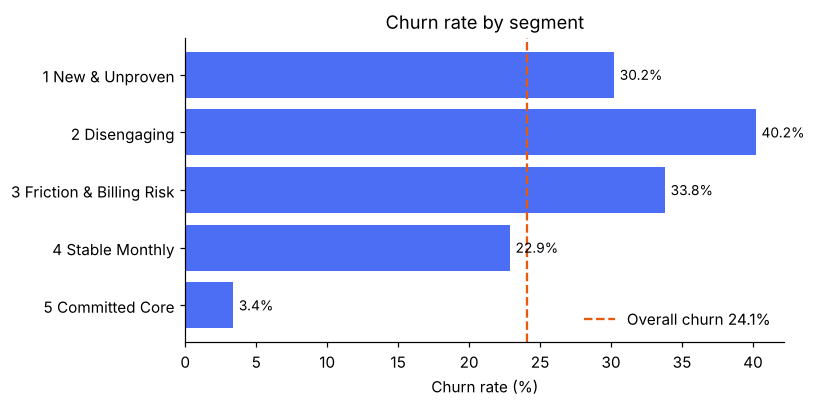

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
s = seg.reset_index()
ax.barh(s.segment, s.churn_rate * 100, color="#4C6EF5")
ax.axvline(base * 100, color="#E8590C", ls="--", lw=1.5, label=f"Overall churn {base:.1%}")
for i, v in enumerate(s.churn_rate * 100):
    ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("Churn rate (%)"); ax.set_title("Churn rate by segment")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 3. Transparent churn-risk score (0-100)
A points system. Each rule adds fixed points; weights were set from the lift table above (stronger and more common signal = more points) and rounded so they sum to exactly 100. No black box: a manager can see *why* any customer scores what they do.

| Rule | Points |
|---|---|
| Monthly contract | 20 |
| Logins down 30%+ vs prior 30 days | 15 |
| 3+ support tickets in 90 days | 15 |
| 2+ late payments in 6 months | 10 |
| No login for 21+ days | 10 |
| Low feature adoption (2 or fewer) | 15 |
| NPS detractor (0-6) | 10 |
| New customer (6 months or less) | 5 |

In [6]:
WEIGHTS = {"is_monthly": 20, "login_drop_30": 15, "high_tickets": 15, "late_pay_2plus": 10,
           "inactive_21d": 10, "low_adoption": 15, "detractor": 10, "new_customer": 5}
assert sum(WEIGHTS.values()) == 100

def risk_score(rec: dict) -> int:
    """Reproducible rule-based churn-risk score from raw fields. Missing NPS adds 0 points (never penalised)."""
    prev = max(rec["logins_prev_30d"], 1)
    pts = 0
    pts += WEIGHTS["is_monthly"] * (rec["contract"] == "Monthly")
    pts += WEIGHTS["login_drop_30"] * ((rec["logins_last_30d"] - rec["logins_prev_30d"]) / prev <= -0.30)
    pts += WEIGHTS["high_tickets"] * (rec["support_tickets_90d"] >= 3)
    pts += WEIGHTS["late_pay_2plus"] * (rec["late_payments_6m"] >= 2)
    pts += WEIGHTS["inactive_21d"] * (rec["days_since_last_login"] >= 21)
    pts += WEIGHTS["low_adoption"] * (rec["features_used"] <= 2)
    nps = rec.get("nps_score")
    pts += WEIGHTS["detractor"] * (nps is not None and not pd.isna(nps) and nps <= 6)
    pts += WEIGHTS["new_customer"] * (rec["tenure_months"] <= 6)
    return int(pts)

df["risk_score"] = [risk_score(r) for r in df.to_dict("records")]
df["risk_tier"] = pd.cut(df.risk_score, [-1, 24, 49, 100], labels=["Low", "Medium", "High"])

band = (df.groupby("risk_tier", observed=True)
          .agg(customers=("customer_id", "count"), churn_rate=("churned", "mean"), avg_mrr=("mrr", "mean")))
band["lift_vs_base"] = band.churn_rate / base
print(band.round(3).to_string())

           customers  churn_rate  avg_mrr  lift_vs_base
risk_tier                                              
Low             2568       0.097   87.476         0.404
Medium          1950       0.317   67.159         1.318
High             476       0.702   59.573         2.913


### Validation: does the score actually rank risk?
1. **Monotonic:** churn should rise with score.
2. **AUC:** probability a random churner scores higher than a random non-churner (0.5 = coin flip).
3. **Capture:** share of all churners found in the top-scored customers.

In [7]:
def auc(y, s):
    r = pd.Series(s).rank(method="average").values
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

y = df.churned.values
print("AUC of risk_score:", round(auc(y, df.risk_score.values), 3))

dec = df.assign(decile=pd.qcut(df.risk_score.rank(method="first"), 10, labels=False) + 1)
by_dec = dec.groupby("decile").churned.mean()
print("\nChurn rate by score decile (10 = highest risk):")
print((by_dec * 100).round(1).to_string())

top = df.sort_values("risk_score", ascending=False)
for pct in (0.10, 0.20, 0.30):
    k = int(len(top) * pct)
    cap_ = top.head(k).churned.sum() / df.churned.sum()
    print(f"Top {int(pct*100)}% by score captures {cap_:.1%} of all churners")

AUC of risk_score: 0.781

Churn rate by score decile (10 = highest risk):
decile
1      2.0
2      4.4
3     13.0
4     13.4
5     14.2
6     19.6
7     28.6
8     35.7
9     40.9
10    69.0
Top 10% by score captures 28.3% of all churners
Top 20% by score captures 45.6% of all churners
Top 30% by score captures 60.3% of all churners


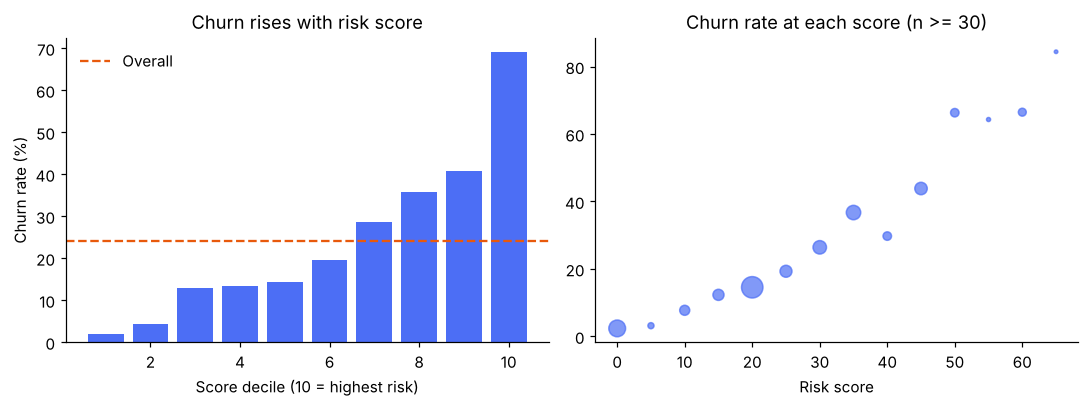

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(by_dec.index, by_dec.values * 100, color="#4C6EF5")
axes[0].axhline(base * 100, color="#E8590C", ls="--", label="Overall")
axes[0].set_xlabel("Score decile (10 = highest risk)"); axes[0].set_ylabel("Churn rate (%)")
axes[0].set_title("Churn rises with risk score"); axes[0].legend(frameon=False)
sc = df.groupby("risk_score").churned.agg(["mean", "count"]); sc = sc[sc["count"] >= 30]
axes[1].scatter(sc.index, sc["mean"] * 100, s=sc["count"] / 6, color="#4C6EF5", alpha=.7)
axes[1].set_xlabel("Risk score"); axes[1].set_title("Churn rate at each score (n >= 30)")
for a in axes: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

### Edge-case validation
The score must behave sensibly on awkward inputs. Each case below has an expected value that is asserted, so the notebook fails loudly if the logic ever breaks.

In [9]:
healthy = dict(contract="Annual", logins_last_30d=30, logins_prev_30d=30, support_tickets_90d=0, late_payments_6m=0,
               days_since_last_login=1, features_used=8, nps_score=9, tenure_months=36)
worst = dict(contract="Monthly", logins_last_30d=0, logins_prev_30d=40, support_tickets_90d=6, late_payments_6m=4,
             days_since_last_login=90, features_used=0, nps_score=1, tenure_months=2)

def variant(base_rec, **kw): return {**base_rec, **kw}

cases = [
    ("Healthy annual customer",                  healthy,                                               0),
    ("Worst case: every rule fires",             worst,                                               100),
    ("Missing NPS is not penalised",             variant(healthy, nps_score=np.nan),                    0),
    ("Missing NPS on worst case (loses 10 pts)", variant(worst, nps_score=np.nan),                     90),
    ("Zero prior logins (no divide-by-zero)",    variant(healthy, logins_prev_30d=0, logins_last_30d=0), 0),
    ("Exactly 30% login drop triggers rule",     variant(healthy, logins_prev_30d=100, logins_last_30d=70), 15),
    ("29% drop does NOT trigger rule",           variant(healthy, logins_prev_30d=100, logins_last_30d=71), 0),
    ("Tenure of exactly 6 months counts as new", variant(healthy, tenure_months=6),                     5),
    ("Login growth is never risky",              variant(healthy, logins_prev_30d=10, logins_last_30d=50), 0),
    ("Annual contract but disengaged",           variant(healthy, logins_last_30d=5, logins_prev_30d=40, days_since_last_login=30), 25),
]
out = []
for name, rec, expected in cases:
    got = risk_score(rec)
    assert got == expected, f"{name}: expected {expected}, got {got}"
    out.append((name, expected, got, "PASS"))
print(pd.DataFrame(out, columns=["edge case", "expected", "got", "result"]).to_string(index=False))

# property checks on the whole dataset
assert df.risk_score.between(0, 100).all()
assert (df.assign(s2=[risk_score(r) for r in df.to_dict("records")]).s2 == df.risk_score).all()   # deterministic
print("\nProperty checks PASS: scores within 0-100, deterministic on re-run.")

                               edge case  expected  got result
                 Healthy annual customer         0    0   PASS
            Worst case: every rule fires       100  100   PASS
            Missing NPS is not penalised         0    0   PASS
Missing NPS on worst case (loses 10 pts)        90   90   PASS
   Zero prior logins (no divide-by-zero)         0    0   PASS
    Exactly 30% login drop triggers rule        15   15   PASS
          29% drop does NOT trigger rule         0    0   PASS
Tenure of exactly 6 months counts as new         5    5   PASS
             Login growth is never risky         0    0   PASS
          Annual contract but disengaged        25   25   PASS

Property checks PASS: scores within 0-100, deterministic on re-run.


## 4. Recommendations by segment
Revenue at risk = segment MRR x segment churn rate (expected monthly revenue lost if nothing changes). Actions are matched to the *reason* the segment churns.

In [10]:
ACTIONS = {
    "1 New & Unproven":          "Guided onboarding: 30/60-day check-ins, activate 3 core features, assign a success contact for Pro/Enterprise.",
    "2 Disengaging":             "Win-back outreach within 7 days of a 30%+ login drop; usage review call; re-share unused features.",
    "3 Friction & Billing Risk": "Escalate open tickets to a named owner; offer billing support / auto-pay; fix root cause before any promo.",
    "4 Stable Monthly":          "Low-cost nudge: offer annual plan with a discount; keep monitoring score monthly.",
    "5 Committed Core":          "Protect, do not discount. Seek referrals and expansion; no retention spend needed.",
}
summary = seg.copy()
summary["total_mrr"] = df.groupby("segment").mrr.sum()
summary["revenue_at_risk"] = summary.total_mrr * summary.churn_rate
summary["avg_risk_score"] = df.groupby("segment").risk_score.mean()
summary["recommended_action"] = summary.index.map(ACTIONS)
summary = summary.reset_index()
summary["priority_rank"] = summary.revenue_at_risk.rank(ascending=False).astype(int)

view = summary[["segment", "customers", "churn_rate", "avg_risk_score", "total_mrr", "revenue_at_risk", "priority_rank"]].copy()
view["churn_rate"] = (view.churn_rate * 100).round(1); view["avg_risk_score"] = view.avg_risk_score.round(1)
view["total_mrr"] = view.total_mrr.round(0); view["revenue_at_risk"] = view.revenue_at_risk.round(0)
print(view.to_string(index=False))

                  segment  customers  churn_rate  avg_risk_score  total_mrr  revenue_at_risk  priority_rank
         1 New & Unproven        609        30.2            30.1    44174.0          13347.0              4
            2 Disengaging        796        40.2            40.9    57558.0          23139.0              2
3 Friction & Billing Risk        574        33.8            35.2    48074.0          16248.0              3
         4 Stable Monthly       2068        22.9            25.5   132448.0          30294.0              1
         5 Committed Core        947         3.4             2.4   101700.0           3437.0              5


In [11]:
import os
os.makedirs("outputs", exist_ok=True)
summary.round(4).to_csv("outputs/segment_table.csv", index=False)
df[["customer_id", "segment", "risk_score", "risk_tier", "churned"]].to_csv("outputs/customer_risk_scores.csv", index=False)
print("Wrote outputs/segment_table.csv and outputs/customer_risk_scores.csv")

Wrote outputs/segment_table.csv and outputs/customer_risk_scores.csv


## 5. Limitations (read before acting on this)
- **Synthetic data:** results show the method works, not that these exact numbers hold for a real business.
- **Association, not causation:** a rule like "monthly contract" flags risk; it does not prove switching someone to annual will stop churn. Test interventions with a holdout group.
- **Score is a ranking, not a probability.** Use tiers for prioritization; do not read a score of 60 as "60% chance".
- **Fixed thresholds** (30% drop, 21 days, etc.) are judgement calls; revisit them quarterly using real outcomes.
- **Timing:** in production, features must be measured *before* the churn window, or the score will leak the answer.